# Example run of DT-LEAMBAS GPU

Example of running the LEMBAS model on toy macrophage data.

In [1]:
import os

import numpy as np
import pandas as pd

from scipy.stats import pearsonr
import torch
import torch.nn as nn

import plotnine as p9

In [2]:
!pwd

/nobackup/users/meimetis/LiverLEMBAS/learning


In [3]:
import sys 
gpu_lembas_path = '/nobackup/users/meimetis/LEMBAS-main'
sys.path.insert(1,os.path.join(gpu_lembas_path))
from LEMBAS.model.bionetwork import format_network, SignalingModel
from LEMBAS.model.train import train_signaling_model
import LEMBAS.utilities as utils
from LEMBAS import plotting, io

In [4]:
import time
import argparse
import logging
from pathlib import Path

In [5]:
args = {
    'DrugsIn':'../preprocessing/preprocessed_data/TrainingValidationData/Hepatocytes_input_conditions.tsv',
    'TargetsIn':'../preprocessing/preprocessed_data/PKN/Hepatocytes_DTI_mask.tsv',
    'TFsOut':'../preprocessing/preprocessed_data/TF_activities/Trimmed_TFacitivities_hepatocytes_microarray.tsv',
    'ChemicalSims':'../preprocessing/preprocessed_data/ChemicalSims/microarray_similarities.csv',
    'PknAnnotation':'../preprocessing/preprocessed_data/PKN/Hepatocytes-PKN-Annotation.tsv',
    'PKN':'../preprocessing/preprocessed_data/PKN/Hepatocytes-PKN-Model.tsv',
    'infoPath':'../preprocessing/preprocessed_data/TrainingValidationData/Hepatocytes_inputdataInfo.tsv',
    'res_dir':'../results/',
    'outPattern':'hepatocytes_dtlembas',
    'no':0,
    'batchSize':35,
    'MoAFactor':0.1,
    'spectralFactor':1e-3,
    'maxIter':1000,
    'noiseLevel':10,
    'L2':1e-6,
    'lamda':1e-7,
    'ConvertToEmpProb':False,
    'inputAmplitude':3,
    'projectionAmplitude':1.2,
    'max_LEMBAS_iterations':100,
    'LEMBAS_leak':0.01,
    'LEMBAS_tolerance':1e-5,
    'drug_bn' : 0.2,
    'drug_drop': 0.1,
    'timepoint':'8 hour',
    'test_dose':'Middle',    
}

In [6]:
DrugsIn = args['DrugsIn']
TargetsIn = args['TargetsIn']
TFsOut = args['TFsOut']
ChemicalSims = args['ChemicalSims']
PknAnnotation = args['PknAnnotation']
PKN = args['PKN']
res_dir = args['res_dir']
infoPath = args['infoPath']
outPattern = args['outPattern']
# outPattern = outPattern + str(args['no'])

In [7]:
logging.basicConfig(level=logging.INFO, format='%(message)s')
logger = logging.getLogger()
print2log = logger.info

# parser = argparse.ArgumentParser(prog='Cell-line simulation')
# parser.add_argument('--DrugsIn', action='store',type = str, default='../preprocessing/preprocessed_data/TrainingValidationData/Hepatocytes_input_conditions.tsv')
# parser.add_argument('--TargetsIn', action='store',type = str, default='../preprocessing/preprocessed_data/PKN/Hepatocytes_DTI_mask.tsv')
# parser.add_argument('--TFsOut', action='store',type = str, default='../preprocessing/preprocessed_data/TF_activities/Trimmed_TFacitivities_hepatocytes_microarray.tsv')
# parser.add_argument('--ChemicalSims', action='store',type = str, default='../preprocessing/preprocessed_data/ChemicalSims/microarray_similarities.csv')
# parser.add_argument('--PKN', action='store',type = str, default='../preprocessing/preprocessed_data/PKN/Hepatocytes-PKN-Model.tsv')
# parser.add_argument('--PknAnnotation', action='store',type = str, default='../preprocessing/preprocessed_data/PKN/Hepatocytes-PKN-Annotation.tsv')
# parser.add_argument('--infoPath', action='store',type = str, default='../preprocessing/preprocessed_data/TrainingValidationData/Hepatocytes_inputdataInfo.tsv')
# parser.add_argument('--res_dir', action='store',type = str, default='../results/')
# parser.add_argument('--model_type', action='store',type = int, default=4)
# parser.add_argument('--outPattern', action='store',type = str, default='hepatocytes_dtlembas')
# parser.add_argument('--no', action='store',type = int, default=0)
# parser.add_argument('--batchSize', action='store',type = int, default=25)
# parser.add_argument('--MoAFactor', action='store',type = float, default=0.1)
# parser.add_argument('--spectralFactor', action='store', default=1e-3)
# parser.add_argument('--maxIter', action='store',type = int, default=2000)
# parser.add_argument('--noiseLevel', action='store',type = float, default=10)
# parser.add_argument('--L2', action='store', default=1e-6)
# parser.add_argument('--lamda', action='store',type = float, default=0.005)
# parser.add_argument('--ConvertToEmpProb', action='store',type = bool, default=False)
# parser.add_argument('--inputAmplitude', action='store',type = float, default=3)
# parser.add_argument('--projectionAmplitude', action='store',type = float, default=1.2)
# parser.add_argument('--LEMBAS_iterations', action='store',type = int, default=120)
# parser.add_argument('--LEMBAS_leak', action='store',type = float, default=0.01)
# parser.add_argument('--LEMBAS_targetPrecision', action='store', default=1e-6)
# parser.add_argument('--drug_bn', action='store', default=0.6)
# parser.add_argument('--drug_drop', action='store', default=0.1)
# parser.add_argument('--timepoint', action='store',type=str, default='8 hour')
# parser.add_argument('--test_dose', action='store',type=str, default='Middle')
# args = parser.parse_args()
# DrugsIn = args.DrugsIn
# TargetsIn = args.TargetsIn
# TFsOut = args.TFsOut
# ChemicalSims = args.ChemicalSims
# PknAnnotation = args.PknAnnotation
# PKN = args.PKN
# res_dir = args.res_dir
# infoPath = args.infoPath
# outPattern = args.outPattern
# outPattern = outPattern + str(args.no)

In [8]:
n_cores = 12
utils.set_cores(n_cores)

seed = 888
if seed:
    torch.use_deterministic_algorithms(True)
    os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
    utils.set_seeds(seed = seed)

device = "cuda" if torch.cuda.is_available() else "cpu"
data_path = res_dir
if not os.path.isdir(data_path):
    os.mkdir(data_path)

In [9]:
# timepoint = args.timepoint
# test_dose = args.test_dose
# res_dir = res_dir + test_dose
timepoint = args['timepoint']
test_dose = args['test_dose']

In [10]:
projection_amplitude_in = args['inputAmplitude']
projection_amplitude_out = args['projectionAmplitude']
ConvertToEmpProb = args['ConvertToEmpProb']

In [11]:
#Setup optimizer
batchSize = args['batchSize']
MoAFactor = args['MoAFactor']
spectralFactor = args['spectralFactor']
maxIter = args['maxIter']
L2 = args['L2']
lamda = args['lamda']

In [12]:
Path(res_dir).mkdir(parents=True, exist_ok=True)

In [13]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

### Load Input Data

In [14]:
# prior knowledge signaling network
net = pd.read_csv(PKN, sep = '\t', index_col = False).loc[:,['source','target','stimulation','inhibition']]

# ligand input and TF output
drugInput = pd.read_csv(DrugsIn, sep = '\t', index_col = 0)
drugSmiles = drugInput.columns.values
TFOutput = pd.read_csv(TFsOut, sep='\t', low_memory=False, index_col=0)
TFOutput = TFOutput.loc[drugInput.index,:]

# Load drugs information
drugTargets = pd.read_csv(TargetsIn, sep='\t', low_memory=False, index_col=0)
inputInfo = pd.read_csv(infoPath, sep='\t', low_memory=False, index_col=0)
inputInfo = inputInfo[inputInfo['time']==timepoint]
TFOutput = TFOutput.loc[inputInfo.index,:]
drugInput = drugInput.loc[inputInfo.index,:]

Let's see what the signaling network looks like:

In [15]:
stimulation_label = 'stimulation'
inhibition_label = 'inhibition'
weight_label = 'mode_of_action'
source_label = 'source'
target_label = 'target'

net[[source_label, target_label, stimulation_label, inhibition_label]].head()

,source,target,stimulation,inhibition
0,Q13255,P48995,1,0
1,P49137,Q16539,0,0
2,Q16539,P49137,1,0
3,P49137,O95453,0,1
4,O60674,P19235,1,0


Let's format it to fit with the necessary inputs to the SignalingModel:

In [16]:
net = format_network(net, weight_label = weight_label, stimulation_label = stimulation_label, inhibition_label = inhibition_label)
net[[source_label, target_label, weight_label, stimulation_label, inhibition_label]].head()

,source,target,mode_of_action,stimulation,inhibition
0,Q13255,P48995,1.0,1,0
1,P49137,Q16539,0.1,0,0
2,Q16539,P49137,1.0,1,0
3,P49137,O95453,-1.0,0,1
4,O60674,P19235,1.0,1,0


In [17]:
nodeNames = np.union1d(net.source.values,net.target.values)

In [18]:
#Subset input and output to intersecting nodes
druginName = drugInput.columns.values
inName = drugTargets.columns.values
outconds = drugInput.index.values
outName = TFOutput.columns.values
inName = np.intersect1d(nodeNames, inName)
outName = np.intersect1d(nodeNames, outName)
TFOutput = TFOutput.loc[outconds,outName]
drugTargets = drugTargets.loc[:,inName]
if ConvertToEmpProb==True:
    print2log('Convereted to Emprirical probabilities')
    TFOutput = 1/(1+np.exp(-TFOutput))

drugTargets = drugTargets.loc[drugInput.columns.values,:]
drugSim = pd.read_csv(ChemicalSims,index_col=0)
drugSim = drugSim.loc[drugInput.columns.values,drugInput.columns.values]
drugSim = torch.tensor(drugSim.values.copy(), dtype=torch.double)

In [19]:
### Split train and test set
print2log('Split train and test set...')
print2log('Kept ' + test_dose + ' as a test set!')
train_ind= inputInfo[~inputInfo.index.str.contains(test_dose)].index.tolist()
test_ind = np.setdiff1d(inputInfo.index.values, train_ind)
drugInput_train = drugInput.loc[train_ind,:]
drugInput_test = drugInput.loc[test_ind,:]
TFOutput_train = TFOutput.loc[train_ind,:]
TFOutput_test = TFOutput.loc[test_ind,:]
X = torch.tensor(drugInput.values.copy(), dtype=torch.double).to(device)
Y = torch.tensor(TFOutput.values, dtype=torch.double).to(device)
# X = torch.tensor(drugInput_train.values.copy(), dtype=torch.double).to(device)
# Y = torch.tensor(TFOutput_train.values, dtype=torch.double).to(device)
X_test = torch.tensor(drugInput_test.values.copy(), dtype=torch.double).to(device)
Y_test = torch.tensor(TFOutput_test.values, dtype=torch.double).to(device)

#### Random shuffle X
#X = X[torch.randperm(X.size()[0]),:]

Split train and test set...
Kept Middle as a test set!


In [20]:
mask_dt =torch.tensor(np.array(drugTargets)).transpose(0,1)

In [21]:
# other parameters
bionet_params = {'target_steps': 100, 'max_steps': args['max_LEMBAS_iterations'], 
                 'exp_factor':50, 'tolerance': args['LEMBAS_tolerance'], 
                 'leak':args['LEMBAS_leak']} # fed directly to model

# training parameters
lr_params = {'max_iter': args['maxIter'], 
             'learning_rate': 1e-2}
other_params = {'batch_size': args['batchSize'], 'noise_level': args['noiseLevel'], 'gradient_noise_level': 1e-9}
regularization_params = {'param_lambda_L2': args['L2'], 'moa_lambda_L1': args['MoAFactor'], 
                         'ligand_lambda_L2': 1e-5, 'uniform_lambda_L2': 1e-5, 
                   'uniform_max': 1/projection_amplitude_out, 'spectral_loss_factor': args['spectralFactor']}
spectral_radius_params = {'n_probes_spectral': 5, 'power_steps_spectral': 50, 'subset_n_spectral': 10}
target_spectral_radius = 0.8
hyper_params = {**lr_params, **other_params, **regularization_params, **spectral_radius_params} # fed into training function

In [22]:
stats = utils.initialize_progress(hyper_params['max_iter'])
# loss and optimizer
criterion = torch.nn.MSELoss(reduction='mean')

In [23]:
mLoss = criterion(torch.mean(Y, dim=0) * torch.ones(Y.shape, device = Y.device), Y)
N = X.shape[0]

## Visualize progress

/nobackup/users/meimetis/anaconda3/envs/gpu_lembas/lib/python3.11/site-packages/plotnine/geoms/geom_path.py:100: PlotnineWarning: geom_path: Removed 601 rows containing missing values.


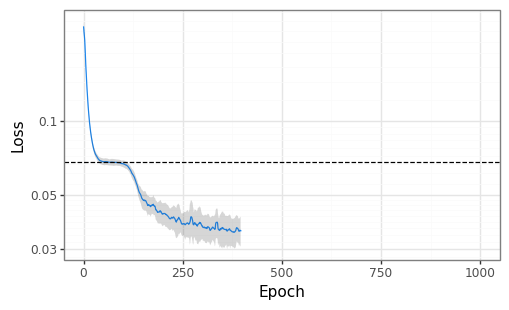

In [32]:
stats = io.read_pickled_object(os.path.join(data_path, 'training_stats.pickle'))
loss_smooth = utils.get_moving_average(values = stats['loss_mean'], n_steps = 5)
loss_sigma_smooth = utils.get_moving_average(values = stats['loss_sigma'], n_steps = 10)
epochs = np.array(range(stats['loss_mean'].shape[0]))

p1A = plotting.shade_plot(X = epochs, Y = loss_smooth, sigma = loss_sigma_smooth, x_label = 'Epoch', y_label = 'Loss')
p1A += p9.scale_y_log10()
p1A += p9.geom_hline(yintercept = mLoss.item(), linetype="dashed", color="black")
p1A.draw()
#p1A.save(filename="fig1A.png", dpi=300) 

As well as how the learning rate was adjusted across training:

/nobackup/users/meimetis/anaconda3/envs/gpu_lembas/lib/python3.11/site-packages/plotnine/geoms/geom_path.py:100: PlotnineWarning: geom_path: Removed 599 rows containing missing values.


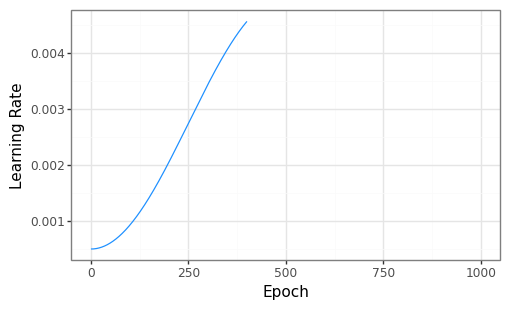

In [29]:
viz_df = pd.DataFrame(data = {'Epoch': epochs, 'lr': stats['learning_rate']})
width, height = 5, 3
p1B = (
    p9.ggplot(viz_df, p9.aes(x='Epoch', y = 'lr')) +
    p9.geom_line(color = '#1E90FF') +
    p9.theme_bw() + 
    p9.theme(figure_size=(width, height)) +
    p9.ylab('Learning Rate')
)
p1B.draw()